In [1]:
import os, sys, mne, socket, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nilearn import plotting

from initialization import load_paths

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
subjID = 99
day = 3
p = load_paths(subjID, day)
montage = mne.channels.make_standard_montage("easycap-M1")

In [5]:
# List all the files in the directory
f_list = os.listdir(p['EEGfiles'])
f_list = [f for f in f_list if f.endswith('.vhdr')]
if len(f_list) == 1:
    raw_data = mne.io.read_raw_brainvision(p['EEGfiles'] + '/' + f_list[0], preload=True)
    raw_data.drop_channels(['LM', 'RM'])
    raw_data.set_montage(montage)


Extracting parameters from /d/DATD/datd/TMS_ori/EEGfiles/sub99/day03/sub99_day03.vhdr...
Setting channel info structure...
Reading 0 ... 4382679  =      0.000 ...  4382.679 secs...


Effective window size : 2.048 (s)


/users/mrugank/.conda/envs/eegmne/lib/python3.12/site-packages/mne/viz/utils.py:165: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


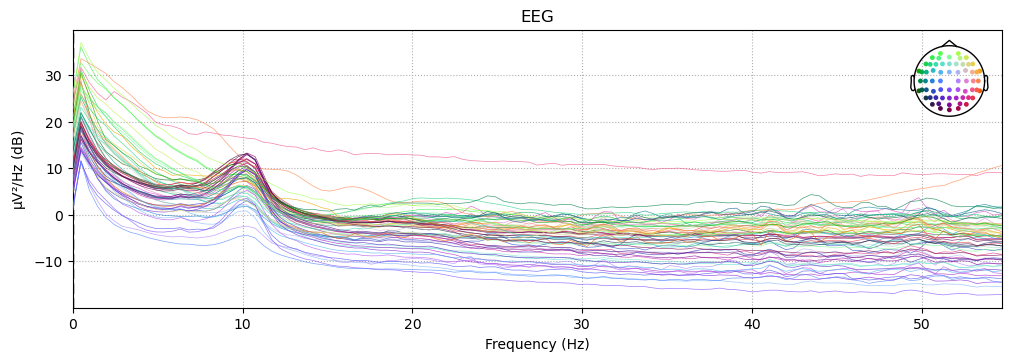

In [6]:
raw_data.compute_psd(fmax=55, average='mean', n_fft=2048).plot()
plt.show()

In [ ]:
raw_data = mne.add_reference_channels(raw_data, ref_channels='Cz')

In [7]:
events, tah = mne.events_from_annotations(raw_data)
events_dict = {
    'BlockOnset': 1001,
    'BlockEnd': 7,
    'Fixation': 1,
    'Delay1': 2,
    'Delay2': 3,
    'Response': 4,
    'Feedback': 5,
    'ITI': 6,
}
trl_events = {
    'inPF': 11,
    'outPF': 10,
}

Used Annotations descriptions: ['Response/R  1', 'Stimulus/S  1', 'Stimulus/S  2', 'Stimulus/S  3', 'Stimulus/S  4', 'Stimulus/S  5', 'Stimulus/S  6', 'Stimulus/S  7', 'Stimulus/S 10', 'Stimulus/S 11']


In [8]:
block_onset_id = events_dict['BlockOnset']
block_end_id = events_dict['BlockEnd']
# Find the start and end events
start_events = events[events[:, 2] == block_onset_id]
end_events = events[events[:, 2] == block_end_id]

# Create custom epochs
epochs_list = []
for start_event in start_events:
    # Find the next end event after the current start event
    end_event = end_events[end_events[:, 0] > start_event[0]][0]

    # Define the time window for the epoch
    tmin = (start_event[0] - raw_data.first_samp) / raw_data.info['sfreq']
    tmax = (end_event[0] - raw_data.first_samp) / raw_data.info['sfreq']

    # Create the epoch
    epoch = raw_data.copy().crop(tmin, tmax)
    epochs_list.append(epoch)

# Concatenate all epochs
# epochs = mne.concatenate_epochs(epochs_list)

In [9]:
# Print duration of the epochs
for epoch in epochs_list:
    print(f'Epoch duration: {epoch.times[-1]:.2f} s')

Epoch duration: 325.72 s
Epoch duration: 277.81 s
Epoch duration: 263.44 s
Epoch duration: 315.32 s
Epoch duration: 265.13 s
Epoch duration: 269.83 s
Epoch duration: 309.08 s
Epoch duration: 302.07 s
Epoch duration: 268.44 s
Epoch duration: 267.91 s
Epoch duration: 264.20 s
Epoch duration: 294.39 s
Epoch duration: 266.80 s


In [ ]:
# Plot sequence of events
